In [12]:
import pandas as pd
import zipfile
from pathlib import PurePosixPath

nombre_zip = "SENAMHI_preparacion_preliminar_respaldo_v1.zip"
nombre_buscado = "senamhi_diario_preliminar.csv"

columnas_necesarias = {
    "CODIGO_ESTACION", "ESTACION", "FECHA_DIA",
    "TEMP_MEDIA_24H", "HR_MEDIA_24H"
}

senamhi_diario_preliminar = None

with zipfile.ZipFile(nombre_zip) as respaldo:
    archivos_csv = [
        ruta for ruta in respaldo.namelist()
        if ruta.lower().endswith(".csv")
        and not ruta.startswith("__MACOSX/")
    ]

    candidatos = [
        ruta for ruta in archivos_csv
        if PurePosixPath(ruta).name.lower() == nombre_buscado
    ]

    # Si cambió el nombre, buscar por las columnas de la base diaria
    if not candidatos:
        for ruta in archivos_csv:
            encabezado = pd.read_csv(
                respaldo.open(ruta),
                encoding="utf-8-sig",
                nrows=0
            )
            if columnas_necesarias.issubset(encabezado.columns):
                candidatos.append(ruta)

    if len(candidatos) == 1:
        senamhi_diario_preliminar = pd.read_csv(
            respaldo.open(candidatos[0]),
            encoding="utf-8-sig",
            dtype={"CODIGO_ESTACION": str},
            parse_dates=["FECHA_DIA"]
        )

        print("Archivo encontrado:", candidatos[0])
        print("Filas cargadas:", len(senamhi_diario_preliminar))
        print(
            "Estaciones:",
            senamhi_diario_preliminar["ESTACION"].nunique()
        )
    else:
        print("No se pudo identificar una única base diaria.")
        print("CSV disponibles dentro del ZIP:")
        for ruta in archivos_csv:
            print(ruta)

Archivo encontrado: SENAMHI_preparacion_preliminar_respaldo_v1/tablas/senamhi_diario_preliminar.csv
Filas cargadas: 4384
Estaciones: 4


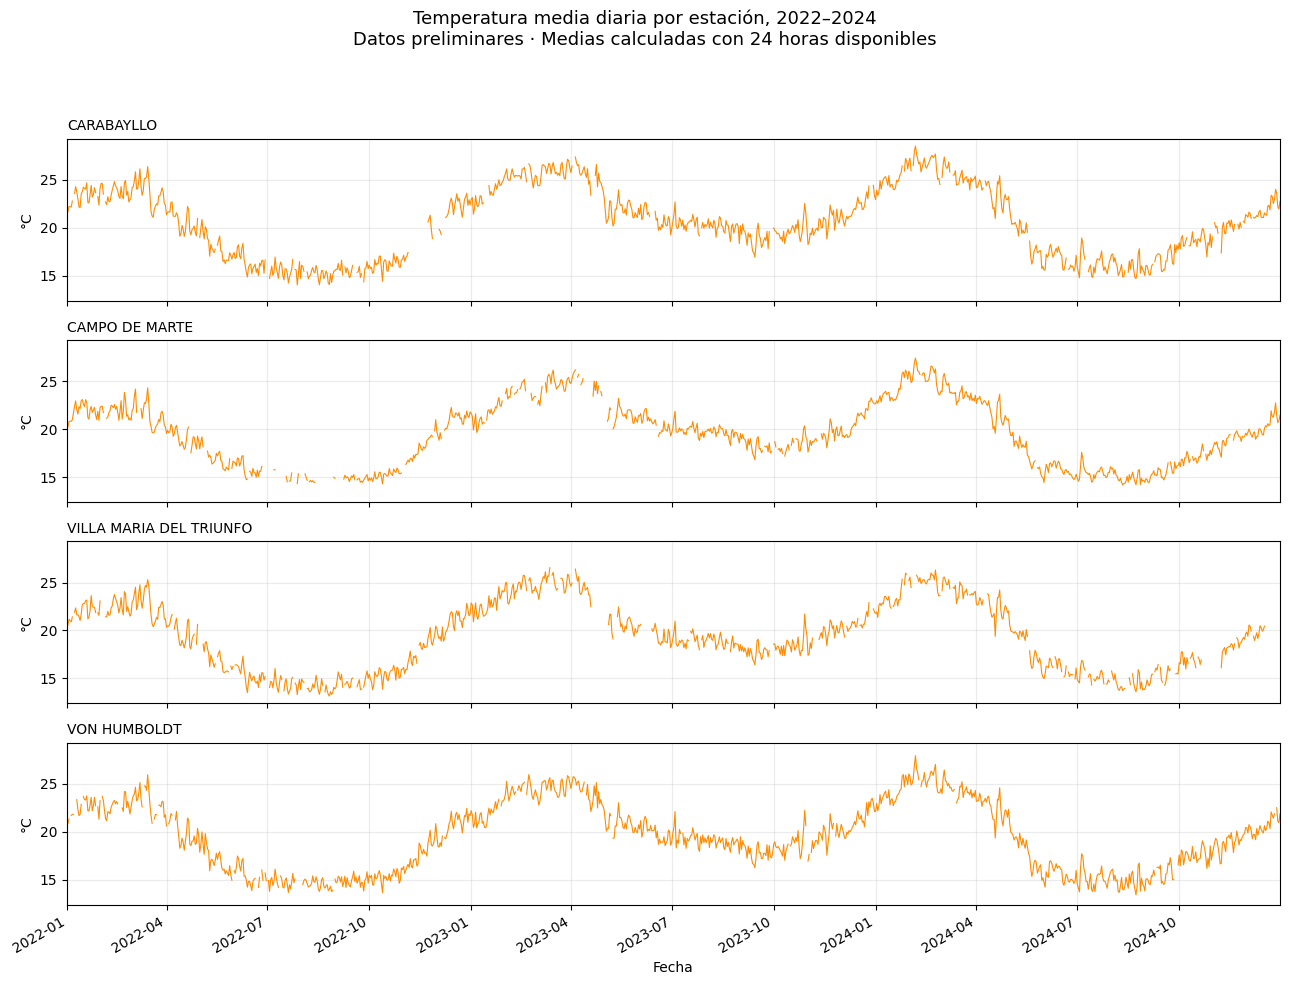

In [13]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

estaciones = [
    "CARABAYLLO",
    "CAMPO DE MARTE",
    "VILLA MARIA DEL TRIUNFO",
    "VON HUMBOLDT"
]

fig, ejes = plt.subplots(
    4, 1, figsize=(13, 10),
    sharex=True, sharey=True
)

for eje, estacion in zip(ejes, estaciones):
    tabla = senamhi_diario_preliminar.loc[
        senamhi_diario_preliminar["ESTACION"].eq(estacion)
    ].sort_values("FECHA_DIA")

    # Conservar NaN permite mostrar los huecos sin unirlos artificialmente
    eje.plot(
        tabla["FECHA_DIA"],
        tabla["TEMP_MEDIA_24H"],
        linewidth=0.8,
        color="darkorange"
    )

    eje.set_title(estacion, loc="left", fontsize=10)
    eje.set_ylabel("°C")
    eje.grid(alpha=0.25)

ejes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ejes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ejes[-1].set_xlabel("Fecha")
ejes[-1].set_xlim(
    pd.Timestamp("2022-01-01"),
    pd.Timestamp("2024-12-31")
)

fig.suptitle(
    "Temperatura media diaria por estación, 2022–2024\n"
    "Datos preliminares · Medias calculadas con 24 horas disponibles",
    fontsize=13
)

fig.autofmt_xdate()
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

In [14]:
resumen_temperatura_anual = (
    senamhi_diario_preliminar
    .assign(ANIO=lambda tabla: tabla["FECHA_DIA"].dt.year)
    .groupby(["ESTACION", "ANIO"], as_index=False)
    .agg(
        DIAS_ESPERADOS=("FECHA_DIA", "size"),
        DIAS_CON_MEDIA=("TEMP_MEDIA_24H", "count"),
        MEDIA_C=("TEMP_MEDIA_24H", "mean"),
        MIN_MEDIA_DIARIA_C=("TEMP_MEDIA_24H", "min"),
        MAX_MEDIA_DIARIA_C=("TEMP_MEDIA_24H", "max")
    )
)

resumen_temperatura_anual["COBERTURA_PCT"] = (
    100
    * resumen_temperatura_anual["DIAS_CON_MEDIA"]
    / resumen_temperatura_anual["DIAS_ESPERADOS"]
)

display(resumen_temperatura_anual.round(2))

,ESTACION,ANIO,DIAS_ESPERADOS,DIAS_CON_MEDIA,MEDIA_C,MIN_MEDIA_DIARIA_C,MAX_MEDIA_DIARIA_C,COBERTURA_PCT
0,CAMPO DE MARTE,2022,365,307,18.34,14.12,24.30,84.11
1,CAMPO DE MARTE,2023,365,328,20.97,16.81,26.18,89.86
2,CAMPO DE MARTE,2024,366,359,19.20,14.17,27.40,98.09
3,CARABAYLLO,2022,365,324,19.10,14.03,26.38,88.77
4,CARABAYLLO,2023,365,344,22.03,16.93,27.38,94.25
5,CARABAYLLO,2024,366,345,20.47,14.68,28.53,94.26
6,VILLA MARIA DEL TRIUNFO,2022,365,336,18.06,13.15,25.30,92.05
7,VILLA MARIA DEL TRIUNFO,2023,365,316,20.83,16.42,26.55,86.58
8,VILLA MARIA DEL TRIUNFO,2024,366,300,19.24,13.59,26.30,81.97
9,VON HUMBOLDT,2022,365,338,18.13,13.47,25.95,92.60


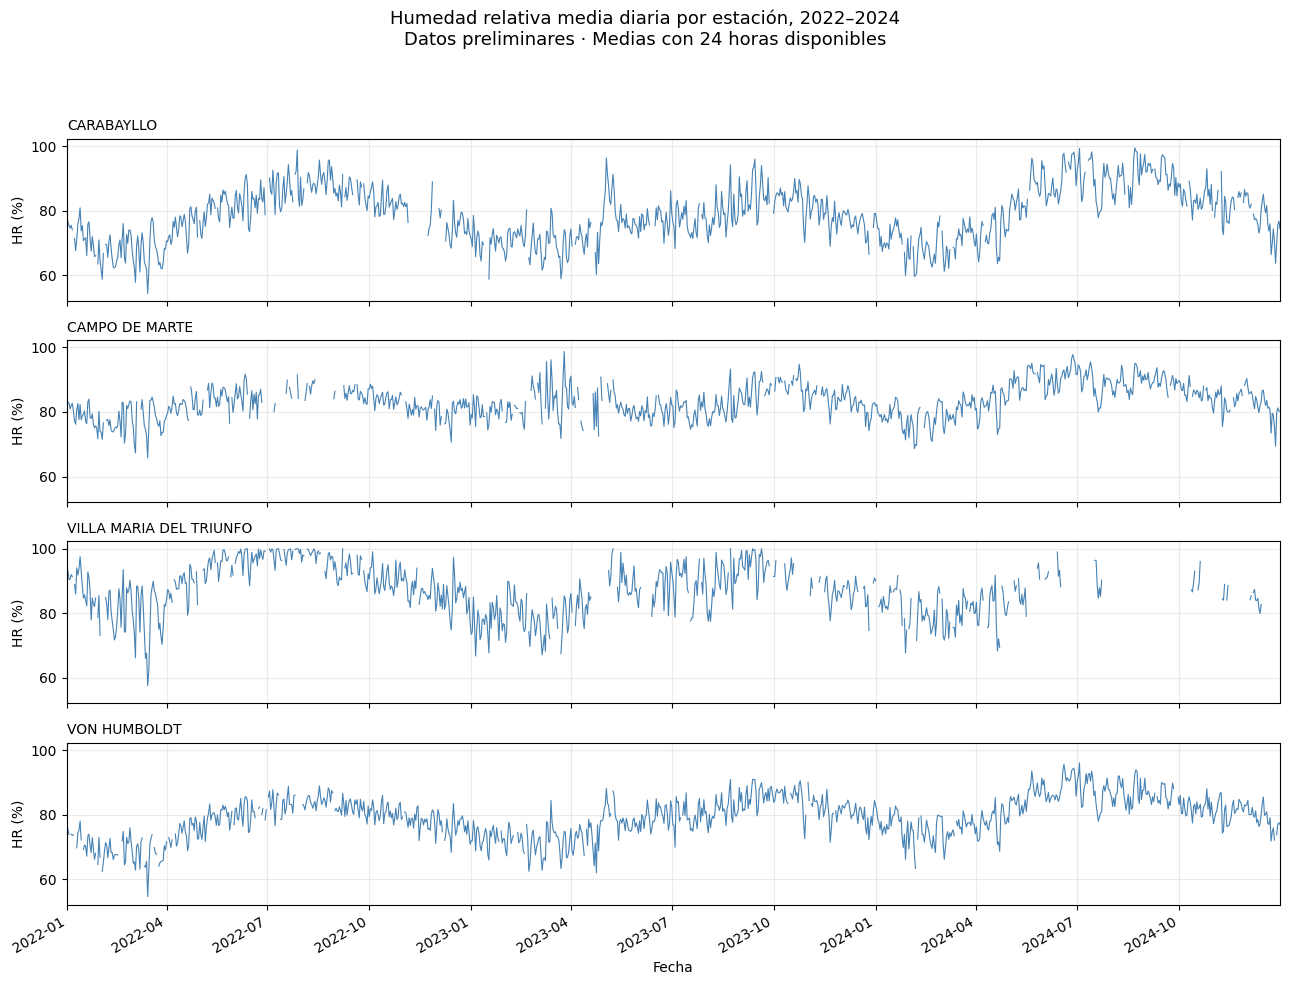

In [15]:
fig_hr, ejes_hr = plt.subplots(
    4, 1, figsize=(13, 10),
    sharex=True, sharey=True
)

for eje, estacion in zip(ejes_hr, estaciones):
    tabla = senamhi_diario_preliminar.loc[
        senamhi_diario_preliminar["ESTACION"].eq(estacion)
    ].sort_values("FECHA_DIA")

    eje.plot(
        tabla["FECHA_DIA"],
        tabla["HR_MEDIA_24H"],
        linewidth=0.8,
        color="steelblue"
    )

    eje.set_title(estacion, loc="left", fontsize=10)
    eje.set_ylabel("HR (%)")
    eje.grid(alpha=0.25)

ejes_hr[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ejes_hr[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ejes_hr[-1].set_xlabel("Fecha")
ejes_hr[-1].set_xlim(
    pd.Timestamp("2022-01-01"),
    pd.Timestamp("2024-12-31")
)

fig_hr.suptitle(
    "Humedad relativa media diaria por estación, 2022–2024\n"
    "Datos preliminares · Medias con 24 horas disponibles",
    fontsize=13
)

fig_hr.autofmt_xdate()
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

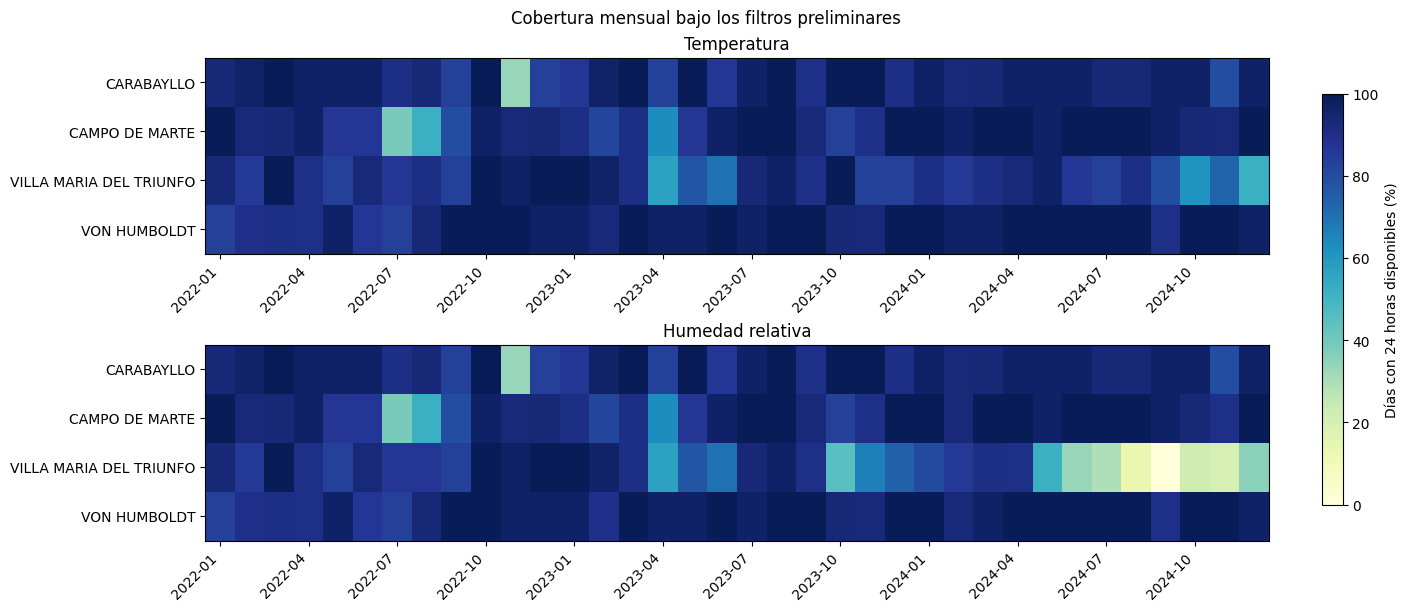

In [16]:
cobertura_mensual = (
    senamhi_diario_preliminar
    .assign(MES=lambda tabla: tabla["FECHA_DIA"].dt.strftime("%Y-%m"))
    .groupby(["ESTACION", "MES"], as_index=False)
    .agg(
        DIAS_ESPERADOS=("FECHA_DIA", "size"),
        DIAS_TEMP=("TEMP_MEDIA_24H", "count"),
        DIAS_HR=("HR_MEDIA_24H", "count")
    )
)

for variable in ["TEMP", "HR"]:
    cobertura_mensual[f"COBERTURA_{variable}_PCT"] = (
        100 * cobertura_mensual[f"DIAS_{variable}"]
        / cobertura_mensual["DIAS_ESPERADOS"]
    )

fig_cobertura, ejes_cobertura = plt.subplots(
    2, 1, figsize=(14, 6), constrained_layout=True
)

for eje, variable, titulo in zip(
    ejes_cobertura,
    ["TEMP", "HR"],
    ["Temperatura", "Humedad relativa"]
):
    matriz = cobertura_mensual.pivot(
        index="ESTACION",
        columns="MES",
        values=f"COBERTURA_{variable}_PCT"
    ).reindex(estaciones)

    imagen = eje.imshow(
        matriz.to_numpy(),
        aspect="auto",
        vmin=0, vmax=100,
        cmap="YlGnBu"
    )

    eje.set_yticks(range(len(estaciones)), labels=estaciones)
    eje.set_xticks(
        range(0, len(matriz.columns), 3),
        labels=matriz.columns[::3],
        rotation=45,
        ha="right"
    )
    eje.set_title(titulo)

fig_cobertura.colorbar(
    imagen,
    ax=ejes_cobertura,
    label="Días con 24 horas disponibles (%)",
    shrink=0.85
)

fig_cobertura.suptitle("Cobertura mensual bajo los filtros preliminares")
plt.show()

In [25]:
import io
import zipfile

nombre_respaldo = "SENAMHI_resultados_descriptivos_preliminares_v1.zip"

figuras = {
    "temperatura_media_diaria.png": fig,
    "humedad_media_diaria.png": fig_hr,
    "cobertura_mensual.png": fig_cobertura
}

tablas = {
    "resumen_temperatura_anual.csv": resumen_temperatura_anual,
    "cobertura_mensual.csv": cobertura_mensual,
    "base_diaria_utilizada.csv": senamhi_diario_preliminar
}

notas = """
RESULTADOS DESCRIPTIVOS PRELIMINARES — SENAMHI 2022-2024

Unidad: estacion-dia. Cuatro estaciones, 4384 filas.
Medias diarias de uso preliminar: requieren 24 horas disponibles
de la respectiva variable, bajo los filtros documentados.

La cobertura mensual representa el porcentaje de dias con media
de 24 horas disponible. No representa cobertura horaria.

Las medias anuales resumen los dias disponibles.
Los faltantes pueden afectar las comparaciones entre anios.
Los minimos y maximos del resumen son de medias diarias.

La humedad de Villa Maria del Triunfo presenta cobertura reducida
en varios meses de 2024. Su validacion sigue pendiente.
Los huecos no fueron interpolados.

Pendientes: confirmacion de zona horaria, representatividad espacial,
asignacion a distritos y evaluacion de los criterios provisionales.
El SINADEF preparado llega hasta el 05/05/2024.
"""

with zipfile.ZipFile(
    nombre_respaldo, "w", compression=zipfile.ZIP_DEFLATED
) as respaldo:

    for nombre, figura in figuras.items():
        imagen = io.BytesIO()
        figura.savefig(
            imagen, format="png", dpi=300, bbox_inches="tight"
        )
        respaldo.writestr("figuras/" + nombre, imagen.getvalue())

    for nombre, tabla in tablas.items():
        respaldo.writestr(
            "tablas/" + nombre,
            tabla.to_csv(index=False, na_rep="").encode("utf-8-sig")
        )

    respaldo.writestr("LEEME_resultados.txt", notas.encode("utf-8"))

with zipfile.ZipFile(nombre_respaldo) as respaldo:
    assert respaldo.testzip() is None, "Error de integridad del ZIP"

print("Respaldo generado: 3 figuras, 3 CSV y notas.")
files.download(nombre_respaldo)

Respaldo generado: 3 figuras, 3 CSV y notas.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Filas distrito-día: 25695
Registros incluidos: 78286
Primera fecha: 2022-01-01
Última fecha: 2024-05-05


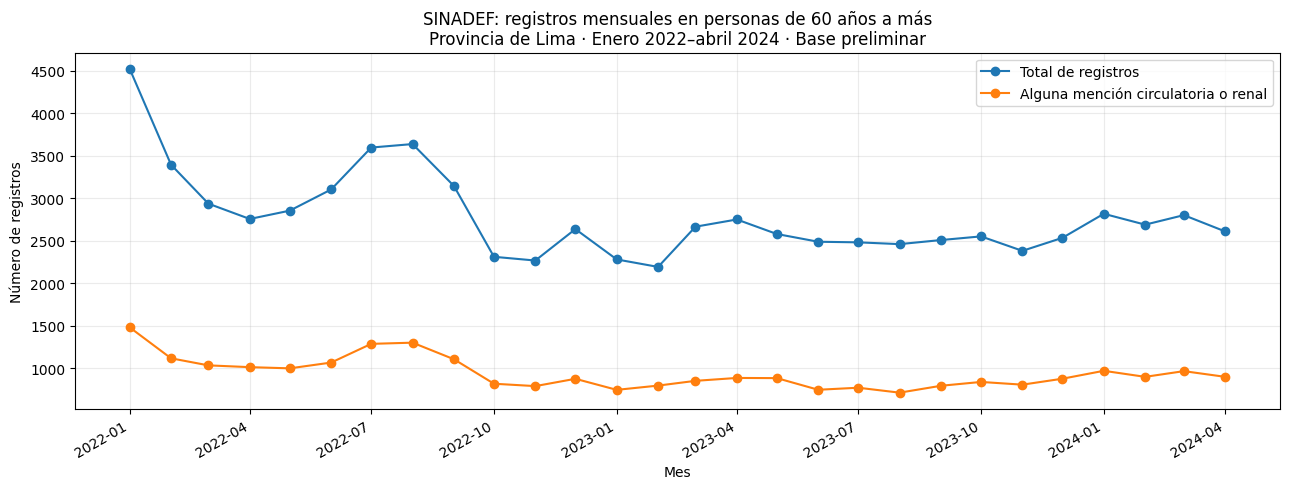

In [20]:
from pathlib import PurePosixPath
import zipfile
import pandas as pd
import matplotlib.pyplot as plt

nombre_csv = "sinadef_lima_60mas_distrito_dia_exploratorio.csv"

with zipfile.ZipFile(
    "SINADEF_preparacion_preliminar_respaldo.zip"
) as respaldo:

    coincidencias = [
        ruta for ruta in respaldo.namelist()
        if PurePosixPath(ruta).name == nombre_csv
    ]
    assert len(coincidencias) == 1, "Revisar ubicación del CSV"

    sinadef_diario = pd.read_csv(
        respaldo.open(coincidencias[0]),
        sep="|",  # Separador confirmado en tu archivo
        encoding="utf-8-sig",
        dtype={"UBIGEO_INEI": str}
    )

sinadef_diario.columns = sinadef_diario.columns.str.strip()

sinadef_diario["FECHA"] = pd.to_datetime(
    sinadef_diario["FECHA"],
    format="%Y-%m-%d",
    errors="raise"
)

columnas = ["N_REGISTROS_TOTAL", "N_ALGUNA_MENCION"]

for columna in columnas:
    sinadef_diario[columna] = pd.to_numeric(
        sinadef_diario[columna], errors="raise"
    )

print("Filas distrito-día:", len(sinadef_diario))
print("Registros incluidos:", sinadef_diario["N_REGISTROS_TOTAL"].sum())
print("Primera fecha:", sinadef_diario["FECHA"].min().date())
print("Última fecha:", sinadef_diario["FECHA"].max().date())

sinadef_mensual = (
    sinadef_diario.set_index("FECHA")[columnas]
    .resample("MS")
    .sum(min_count=1)
)

# Mayo de 2024 se conserva en la tabla como mes parcial
grafico_mensual = sinadef_mensual.loc["2022-01-01":"2024-04-01"]

fig_sinadef, eje = plt.subplots(figsize=(13, 5))

eje.plot(
    grafico_mensual.index,
    grafico_mensual["N_REGISTROS_TOTAL"],
    marker="o", label="Total de registros"
)

eje.plot(
    grafico_mensual.index,
    grafico_mensual["N_ALGUNA_MENCION"],
    marker="o", label="Alguna mención circulatoria o renal"
)

eje.set_title(
    "SINADEF: registros mensuales en personas de 60 años a más\n"
    "Provincia de Lima · Enero 2022–abril 2024 · Base preliminar"
)
eje.set_ylabel("Número de registros")
eje.set_xlabel("Mes")
eje.grid(alpha=0.25)
eje.legend()

fig_sinadef.autofmt_xdate()
plt.tight_layout()
plt.show()

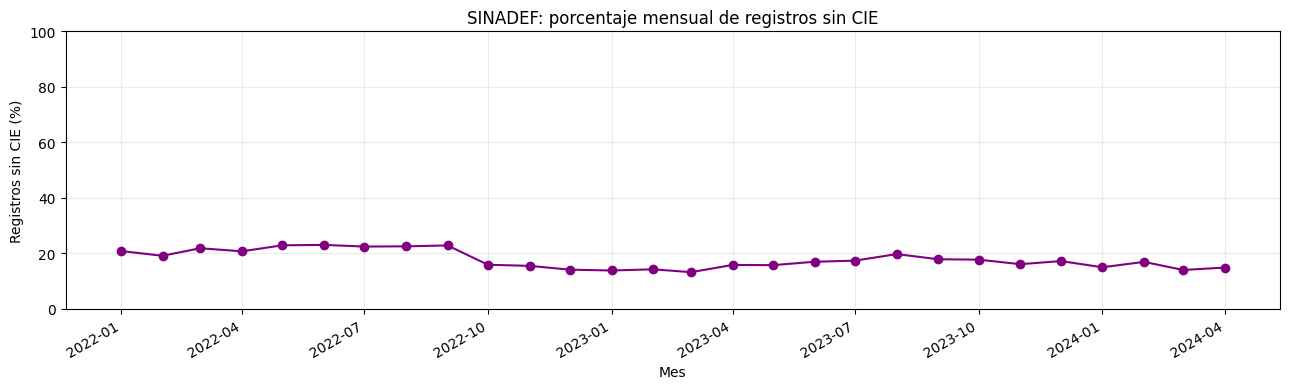

In [21]:
columnas_calidad = [
    "N_REGISTROS_TOTAL", "N_CON_CIE", "N_SIN_CIE"
]

for columna in columnas_calidad:
    sinadef_diario[columna] = pd.to_numeric(
        sinadef_diario[columna], errors="raise"
    )

assert (
    sinadef_diario["N_CON_CIE"]
    + sinadef_diario["N_SIN_CIE"]
    == sinadef_diario["N_REGISTROS_TOTAL"]
).all(), "Los conteos de disponibilidad de CIE no coinciden"

calidad_mensual_sinadef = (
    sinadef_diario.set_index("FECHA")[columnas_calidad]
    .resample("MS")
    .sum(min_count=1)
)

calidad_mensual_sinadef["PCT_SIN_CIE"] = (
    100 * calidad_mensual_sinadef["N_SIN_CIE"]
    / calidad_mensual_sinadef["N_REGISTROS_TOTAL"].where(
        calidad_mensual_sinadef["N_REGISTROS_TOTAL"].gt(0)
    )
)

tabla_grafico = calidad_mensual_sinadef.loc[
    "2022-01-01":"2024-04-01"
]

fig_calidad_sinadef, eje = plt.subplots(figsize=(13, 4))

eje.plot(
    tabla_grafico.index,
    tabla_grafico["PCT_SIN_CIE"],
    marker="o",
    color="purple"
)

eje.set_title("SINADEF: porcentaje mensual de registros sin CIE")
eje.set_ylabel("Registros sin CIE (%)")
eje.set_xlabel("Mes")
eje.set_ylim(0, 100)
eje.grid(alpha=0.25)

fig_calidad_sinadef.autofmt_xdate()
plt.tight_layout()
plt.show()

In [22]:
columnas_resumen = [
    "N_REGISTROS_TOTAL",
    "N_ALGUNA_MENCION",
    "N_SIN_CIE"
]

for columna in columnas_resumen:
    sinadef_diario[columna] = pd.to_numeric(
        sinadef_diario[columna], errors="raise"
    )

resumen_sinadef_comparable = (
    sinadef_diario.loc[sinadef_diario["FECHA"].dt.month.le(4)]
    .assign(ANIO=lambda tabla: tabla["FECHA"].dt.year)
    .groupby("ANIO", as_index=False)
    .agg(
        DIAS_CON_REGISTROS=("FECHA", "nunique"),
        REGISTROS_TOTAL=("N_REGISTROS_TOTAL", "sum"),
        CON_ALGUNA_MENCION=("N_ALGUNA_MENCION", "sum"),
        SIN_CIE=("N_SIN_CIE", "sum")
    )
)

resumen_sinadef_comparable["PCT_SIN_CIE"] = (
    100 * resumen_sinadef_comparable["SIN_CIE"]
    / resumen_sinadef_comparable["REGISTROS_TOTAL"]
)

display(resumen_sinadef_comparable.round(2))

,ANIO,DIAS_CON_REGISTROS,REGISTROS_TOTAL,CON_ALGUNA_MENCION,SIN_CIE,PCT_SIN_CIE
0,2022,120,13604,4641,2803,20.60
1,2023,120,9883,3276,1414,14.31
2,2024,121,10912,3730,1657,15.19


Distritos incluidos en el resumen: 43


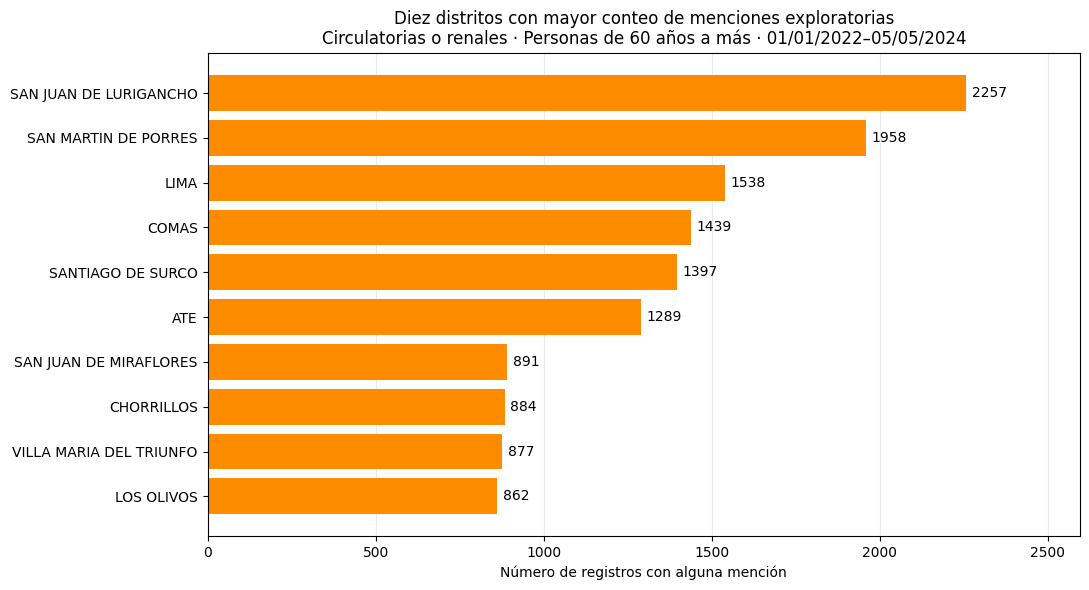

In [23]:
resumen_distrital_sinadef = (
    sinadef_diario.groupby(
        ["UBIGEO_INEI", "DISTRITO"], as_index=False
    )
    .agg(
        REGISTROS_TOTAL=("N_REGISTROS_TOTAL", "sum"),
        CON_ALGUNA_MENCION=("N_ALGUNA_MENCION", "sum"),
        SIN_CIE=("N_SIN_CIE", "sum"),
        DIAS_CON_REGISTROS=("FECHA", "nunique")
    )
)

resumen_distrital_sinadef["PCT_SIN_CIE"] = (
    100 * resumen_distrital_sinadef["SIN_CIE"]
    / resumen_distrital_sinadef["REGISTROS_TOTAL"].where(
        resumen_distrital_sinadef["REGISTROS_TOTAL"].gt(0)
    )
)

resumen_distrital_sinadef = resumen_distrital_sinadef.sort_values(
    "CON_ALGUNA_MENCION", ascending=False
)

diez_distritos = (
    resumen_distrital_sinadef.head(10)
    .sort_values("CON_ALGUNA_MENCION")
)

fig_distritos_sinadef, eje = plt.subplots(figsize=(11, 6))

barras = eje.barh(
    diez_distritos["DISTRITO"],
    diez_distritos["CON_ALGUNA_MENCION"],
    color="darkorange"
)
eje.bar_label(barras, padding=4, fmt="%.0f")
eje.margins(x=0.15)

eje.set_title(
    "Diez distritos con mayor conteo de menciones exploratorias\n"
    "Circulatorias o renales · Personas de 60 años a más · "
    "01/01/2022–05/05/2024"
)
eje.set_xlabel("Número de registros con alguna mención")
eje.grid(axis="x", alpha=0.25)
eje.set_axisbelow(True)

plt.tight_layout()
print("Distritos incluidos en el resumen:",
      len(resumen_distrital_sinadef))
plt.show()

In [24]:
import io
import zipfile
from google.colab import files

nombre_respaldo = "SINADEF_resultados_descriptivos_preliminares_v1.zip"

figuras_sinadef = {
    "registros_mensuales.png": fig_sinadef,
    "porcentaje_sin_cie.png": fig_calidad_sinadef,
    "diez_distritos_menciones.png": fig_distritos_sinadef
}

tablas_sinadef = {
    "base_diaria_utilizada.csv": sinadef_diario,
    "resumen_mensual_registros.csv": sinadef_mensual.reset_index(),
    "calidad_mensual.csv": calidad_mensual_sinadef.reset_index(),
    "comparacion_enero_abril.csv": resumen_sinadef_comparable,
    "resumen_distrital.csv": resumen_distrital_sinadef
}

notas = """
RESULTADOS DESCRIPTIVOS PRELIMINARES — SINADEF

Poblacion seleccionada: personas de 60 anios a mas,
residentes de la provincia de Lima, con distrito identificado.
Periodo disponible: 01/01/2022 al 05/05/2024.

Base utilizada: 25695 filas distrito-dia y 78286 registros.
Los 11 registros sin ubicacion distrital resuelta permanecen
apartados en el respaldo de preparacion previo.

Las menciones circulatorias o renales son exploratorias:
se buscaron en los campos CIE disponibles.
No equivalen a causa basica confirmada ni a casos confirmados
de lesion cardiorrenal inducida por calor.
La union cuenta una sola vez los registros con ambas menciones.

Las graficas mensuales muestran enero de 2022 a abril de 2024.
Mayo de 2024 es parcial y permanece conservado en las tablas.

La comparacion entre anios utiliza enero-abril.
2024 incluye el 29 de febrero.
La ausencia de CIE varia entre periodos y limita la clasificacion.

La comparacion distrital utiliza conteos absolutos por residencia.
No representa tasas ni una clasificacion de riesgo poblacional.

Los dias sin filas no fueron convertidos automaticamente en ceros.
Este analisis no evalua aun asociaciones con temperatura.

CSV exportados con separador | y codificacion UTF-8 con BOM.
Leer UBIGEO_INEI como texto al volver a cargar.
"""

with zipfile.ZipFile(
    nombre_respaldo, "w", compression=zipfile.ZIP_DEFLATED
) as respaldo:

    for nombre, figura in figuras_sinadef.items():
        imagen = io.BytesIO()
        figura.savefig(
            imagen, format="png", dpi=300, bbox_inches="tight"
        )
        respaldo.writestr("figuras/" + nombre, imagen.getvalue())

    for nombre, tabla in tablas_sinadef.items():
        respaldo.writestr(
            "tablas/" + nombre,
            tabla.to_csv(
                index=False, sep="|", na_rep=""
            ).encode("utf-8-sig")
        )

    respaldo.writestr("LEEME_resultados.txt", notas.encode("utf-8"))

with zipfile.ZipFile(nombre_respaldo) as respaldo:
    assert respaldo.testzip() is None, "Error de integridad del ZIP"

print("Respaldo generado: 3 figuras, 5 CSV y notas.")
files.download(nombre_respaldo)

Respaldo generado: 3 figuras, 5 CSV y notas.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>